# How the Stringer et al. 2019 spreadsheet is measured

1. **The behaviour.** There is no task: what the mouse does, and how its face video becomes the behaviour signal.
2. **What is in Stringer 2019?** The eight-probe release: which mice, which files, what we kept.
3. **From that, how do we get the spreadsheet numbers?** Subjects, neurons, length, sizes (there are no trials).
4. **Figures.** Probes in the brain, neurons per probe, firing rates, regions, raster with face motion.

The data lives on HAL (`~/ismael/stringer2019/data`: the 2.1 GB spikes + face-motion release and the 36.4 GB raw
face videos). `data/stringer2019/stringer_extract.py` reduced it there to the small tables in
`data/stringer2019/tables/` (5 MB), which this notebook reads.

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 160)

here = Path.cwd().resolve()
REPO = here
for candidate in [here, *here.parents]:
    if (candidate / "src" / "ladys").is_dir() or (candidate / "data" / "stringer2019" / "tables").exists():
        REPO = candidate
        break
TABLES = REPO / "data" / "stringer2019" / "tables"
FIGURE_DIR = REPO / "tutorials" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
assert TABLES.exists(), f"Expected extracted tables at {TABLES}; see data/stringer2019/README.md"
GB = 1e9
MICE = ["Krebs", "Waksman", "Robbins"]
MOUSE_COLOR = {"Krebs": "#1b9e77", "Waksman": "#d95f02", "Robbins": "#7570b3"}

sessions = pd.read_parquet(TABLES / "sessions.parquet").set_index("session").loc[MICE].reset_index()
probes = pd.read_parquet(TABLES / "probes.parquet")
units = pd.read_parquet(TABLES / "units.parquet")
release = pd.read_csv(TABLES / "release_files.csv")
display(sessions[["session", "probes", "units", "spikes", "length_min", "spont_start", "spont_end", "face_frames",
                  "face_fps"]].round(1))

,session,probes,units,spikes,length_min,spont_start,spont_end,face_frames,face_fps
0,Krebs,8,1462,11613905,21.7,3811,5150.2,202473,39.6
1,Waksman,8,2688,41060779,41.4,3633,6153.6,242523,39.6
2,Robbins,8,2296,44749657,37.1,3323,5574.4,219488,39.6


## 1. The behaviour (there is no task)

Paper Fig. 2A–C (top: how the face video becomes the behaviour signal) and Fig. 3A–B (bottom: the 8 probes of each
mouse, and a histology section with the probe tracks) (Stringer et al. 2019, author manuscript):

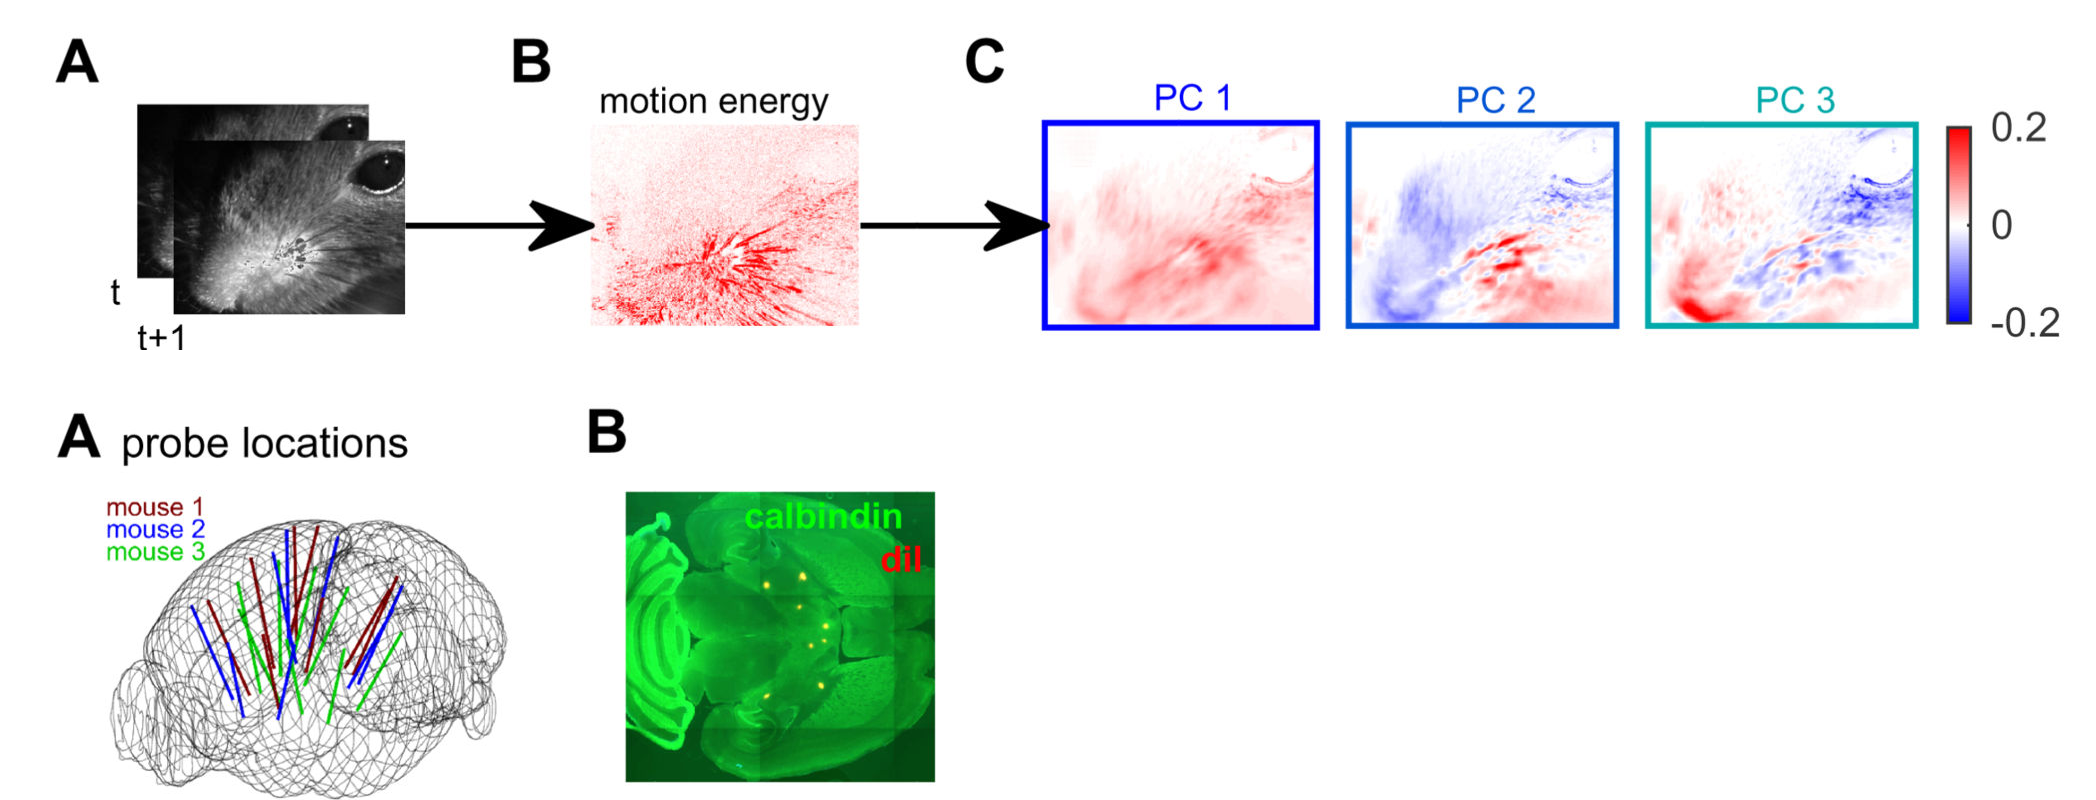

In [2]:
display(Image(filename=str(FIGURE_DIR / "stringer_paper_setup.png"), width=900))

**What the mouse does.** Nothing it was trained for. It is head-fixed, awake, and free to turn a wheel with its front
paws, with no stimulus and no reward, for about an hour. On its own it runs, whisks, sniffs and moves its face.

**What is recorded at the same time.**
1. **Spikes** from 8 Neuropixels probes at once (both hemispheres: frontal, sensorimotor, visual and retrosplenial
   cortex, hippocampus, striatum, thalamus, midbrain).
2. **A face video** from an infrared camera (~40 Hz in this release).

**How the video becomes behaviour labels** (Fig. 2A–C):
1. Motion energy: the absolute difference of consecutive frames (where the face moved).
2. SVD of the motion-energy movie: 500 spatial masks (Fig. 2C shows the top 3) and, for each frame, 500
   component values (`motionSVD`, frames × 500). Those component time courses are the behaviour labels.

The paper's point is that these face-motion components predict a large part of the spontaneous activity across the
whole brain. For a benchmark, the targets are the face-motion components (or the spikes themselves); there are no
trials, conditions or stimuli.

**Session layout.** Each mouse has one recording. The face video runs from the start of the recording, but spikes are
released only for its last part, the spontaneous window (from tstart in `ephysLoad.m`, 55–64 min in, to the last
video frame). Below: the span of the released spikes, the spontaneous window and the face video, per mouse. Only the
face frames inside the spontaneous window go with spikes, so only those count toward the benchmark size.

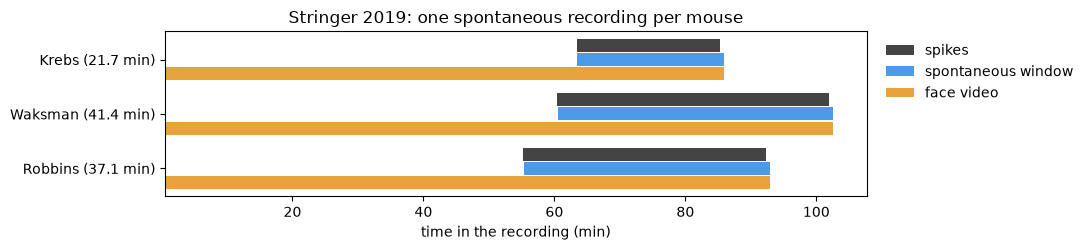

,t_first (min),t_last (min),spont_start (min),spont_end (min),face_t0 (min),face_t1 (min),face_fps
session,,,,,,,
Krebs,63.52,85.21,63.52,85.84,0.64,85.84,39.61
Waksman,60.44,101.87,60.55,102.56,0.52,102.56,39.61
Robbins,55.18,92.28,55.38,92.91,0.55,92.91,39.61


In [3]:
fig, ax = plt.subplots(figsize=(11, 2.6))
spans = [("spikes", "t_first", "t_last", "#444444"), ("spontaneous window", "spont_start", "spont_end", "#4c9be8"),
         ("face video", "face_t0", "face_t1", "#e8a33d")]
for i, m in enumerate(MICE):
    s = sessions.set_index("session").loc[m]
    for j, (label, a, b, color) in enumerate(spans):
        ax.barh(i + (j - 1) * 0.26, (s[b] - s[a]) / 60, left=s[a] / 60, height=0.24, color=color,
                label=label if i == 0 else None)
ax.set_yticks(range(len(MICE)), [f"{m} ({sessions.set_index('session').loc[m, 'length_min']:.1f} min)" for m in MICE])
ax.invert_yaxis()
ax.set_xlabel("time in the recording (min)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.set_title("Stringer 2019: one spontaneous recording per mouse")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "stringer_session_timeline.png", dpi=150, bbox_inches="tight")
plt.show()
display(sessions.set_index("session")[["t_first", "t_last", "spont_start", "spont_end", "face_t0", "face_t1",
                                       "face_fps"]].div([60] * 6 + [1]).round(2)
        .rename(columns=lambda c: c if c == "face_fps" else f"{c} (min)"))

## 2. What is in Stringer 2019

- **Release**: "Eight-probe Neuropixels recordings during spontaneous behaviors" (Steinmetz, Pachitariu, Stringer,
  Carandini, Harris; Janelia figshare, [10.25378/janelia.7739750](https://doi.org/10.25378/janelia.7739750), v4,
  **CC BY-NC 4.0**), the electrophysiology behind Stringer et al. 2019, *Spontaneous behaviors drive
  multidimensional, brainwide activity*, Science 364:eaav7893. Raw face videos are a separate item,
  [10.25378/janelia.8378360](https://doi.org/10.25378/janelia.8378360) (**CC BY 4.0**).
- **3 mice** (Krebs, Waksman, Robbins), **one session each**, **8 Neuropixels probes recorded at once**, in both
  hemispheres: frontal and sensorimotor cortex, visual cortex, hippocampus, striatum, thalamus, midbrain.
- **No task and no stimuli**: spontaneous activity of a head-fixed mouse, with its face filmed (~40 Hz).
  The behaviour signal is that video, reduced by SVD to 500 face-motion components.
- **Spikes are the rawest public form**: no raw voltage, no LFP, no unit QC labels or waveforms.

| File | What | Used for |
|---|---|---|
| `spks/spks{mouse}_Feb18.mat` | per probe: spike times `st` (s), cluster `clu`, cluster height on the probe `Wheights` (µm) | NEURONS, LENGTH, rates |
| `faces/{mouse}_face_proc.mat` | `motionSVD` (frames × 500), `motionMask` (pixels × 500), frame `times` (s, spike clock) | behaviour labels |
| `probeLocations.mat` | per probe: name, 384 sites' CCF position (µm) and CCF label, site heights | regions |
| `probeBorders.mat` | per probe: the authors' coarse areas (e.g. V1, HPF, TH) by height | coarse regions |
| `ephysLoad.m` | the authors' MATLAB loader (spontaneous-window start per mouse, unit → area) | conventions |
| `EightProbeVideos.zip` (other item) | raw face videos | RAW size only |

**Probe pairing.** `ephysLoad.m` pairs `spks(k)` with `probeLocations(mouse).probe(k)`, used here. The authors'
analysis code (`alignFaces30Hz.m`) instead reorders the probes with `[1 2 7 8 3 4 5 6]`. Tests on units at
out-of-brain sites and on correlations between probes did not settle which is right, so the per-unit regions carry
that uncertainty (the per-mouse totals do not).

**Checks against the paper.** The paper reports 2,296, 2,668 and 1,462 units. Krebs and Robbins match the release
exactly; Waksman has 2,688 clusters in the release, 20 more than the paper. Every released cluster fires inside the
spontaneous window, and the released spike times start at most 12 s before that window: the release holds only the
spontaneous period.

In [4]:
paper = {"Krebs": 1462, "Waksman": 2668, "Robbins": 2296}
chk = sessions.set_index("session")[["probes", "units", "units_with_spont_spikes"]].assign(paper_units=pd.Series(paper))
display(chk)
assert (chk.probes == 8).all() and (chk.units == chk.units_with_spont_spikes).all()
assert chk.loc[["Krebs", "Robbins"], "units"].tolist() == [1462, 2296]
assert probes.groupby("session").units.sum().loc[MICE].tolist() == sessions.units.tolist() == [1462, 2688, 2296]
display(release.assign(GB=release.size_bytes / GB).drop(columns="size_bytes").round(3))

,probes,units,units_with_spont_spikes,paper_units
session,,,,
Krebs,8,1462,1462,1462
Waksman,8,2688,2688,2668
Robbins,8,2296,2296,2296


,item,article,license,name,GB
0,spikes_behaviour,7739750,CC BY-NC 4.0,faces.zip,1.397
1,spikes_behaviour,7739750,CC BY-NC 4.0,spks.zip,0.721
2,spikes_behaviour,7739750,CC BY-NC 4.0,ephysLoad.m,0.000
3,spikes_behaviour,7739750,CC BY-NC 4.0,probeLocations.mat,0.000
4,spikes_behaviour,7739750,CC BY-NC 4.0,probeBorders.mat,0.000
5,raw_videos,8378360,CC BY 4.0,eyeFrame.PNG,0.000
6,raw_videos,8378360,CC BY 4.0,EightProbeVideos.zip,36.391


## 3. How those files become spreadsheet numbers

- **SUBJECTS**: mice, 3. One session per mouse.
- **TRIALS**: `N/A`. Spontaneous activity; no task, no stimulus, no trial structure.
- **NEURONS**: every released cluster (the release has no QC labels, and the authors analyse all of them).
  TOTAL = sum; MEDIAN = per session (all 8 probes are simultaneous).
- **LENGTH**: first-to-last spike per session, summed. Equal to the spontaneous window (tstart in `ephysLoad.m` to the
  last face-video frame) within a minute.
- **RAW**: everything public for these recordings: the spikes + face-motion item and the raw-video item.
- **BENCHMARK**: what a spiking benchmark needs, at its in-memory size: spike times (float64) + cluster ids (uint32),
  12 bytes per spike; face-motion SVD (float32, frames × 500) + frame times (float64) for the frames inside the
  spontaneous window (the video starts ~1 h before the released spikes; the frame rate is constant, so frames =
  overlap × fps); probe locations. The SVD spatial masks (`motionMask`), the face frames before the spontaneous
  window and the raw videos are left out.
- **CHANNELS**: `N/A` (sorted units).

In [5]:
overlap = (np.minimum(sessions.spont_end, sessions.face_t1) - np.maximum(sessions.spont_start, sessions.face_t0))
sessions["face_frames_spont"] = (overlap * sessions.face_fps).round().astype(int)
face_bytes = (sessions.face_frames_spont * sessions.face_svd_components * 4 + sessions.face_frames_spont * 8).sum()
display(sessions[["session", "face_frames", "face_frames_spont"]])
spike_bytes = sessions.spikes.sum() * 12
probe_bytes = release.loc[release.name.isin(["probeLocations.mat", "probeBorders.mat"]), "size_bytes"].sum()
raw_bytes = release.size_bytes.sum()
benchmark_bytes = spike_bytes + face_bytes + probe_bytes
summary = pd.Series({
    "subjects": len(sessions), "total neurons": sessions.units.sum(), "median neurons": sessions.units.median(),
    "length (min)": round(sessions.length_min.sum(), 1), "raw (GB)": round(raw_bytes / GB, 3),
    "benchmark (GB)": round(benchmark_bytes / GB, 3), "  spikes (GB)": round(spike_bytes / GB, 3),
    "  face motion SVD (GB)": round(face_bytes / GB, 3)})
display(summary.to_frame("value"))

,session,face_frames,face_frames_spont
0,Krebs,202473,53045
1,Waksman,242523,99843
2,Robbins,219488,89181


,value
subjects,3.000
total neurons,6446.000
median neurons,2296.000
length (min),100.200
raw (GB),38.509
benchmark (GB),1.655
spikes (GB),1.169
face motion SVD (GB),0.486


## 4. Figures

### Probes in the brain

All 24 probes, drawn through their in-brain sites (`stringer_probes.png`, rendered with brainrender outside this
notebook; positions from `probeLocations.mat`). Each mouse has the same 8 probe names (ZO, K1–K3, ZNP1–4), but
their paths differ between mice (see the labels under the bars below).

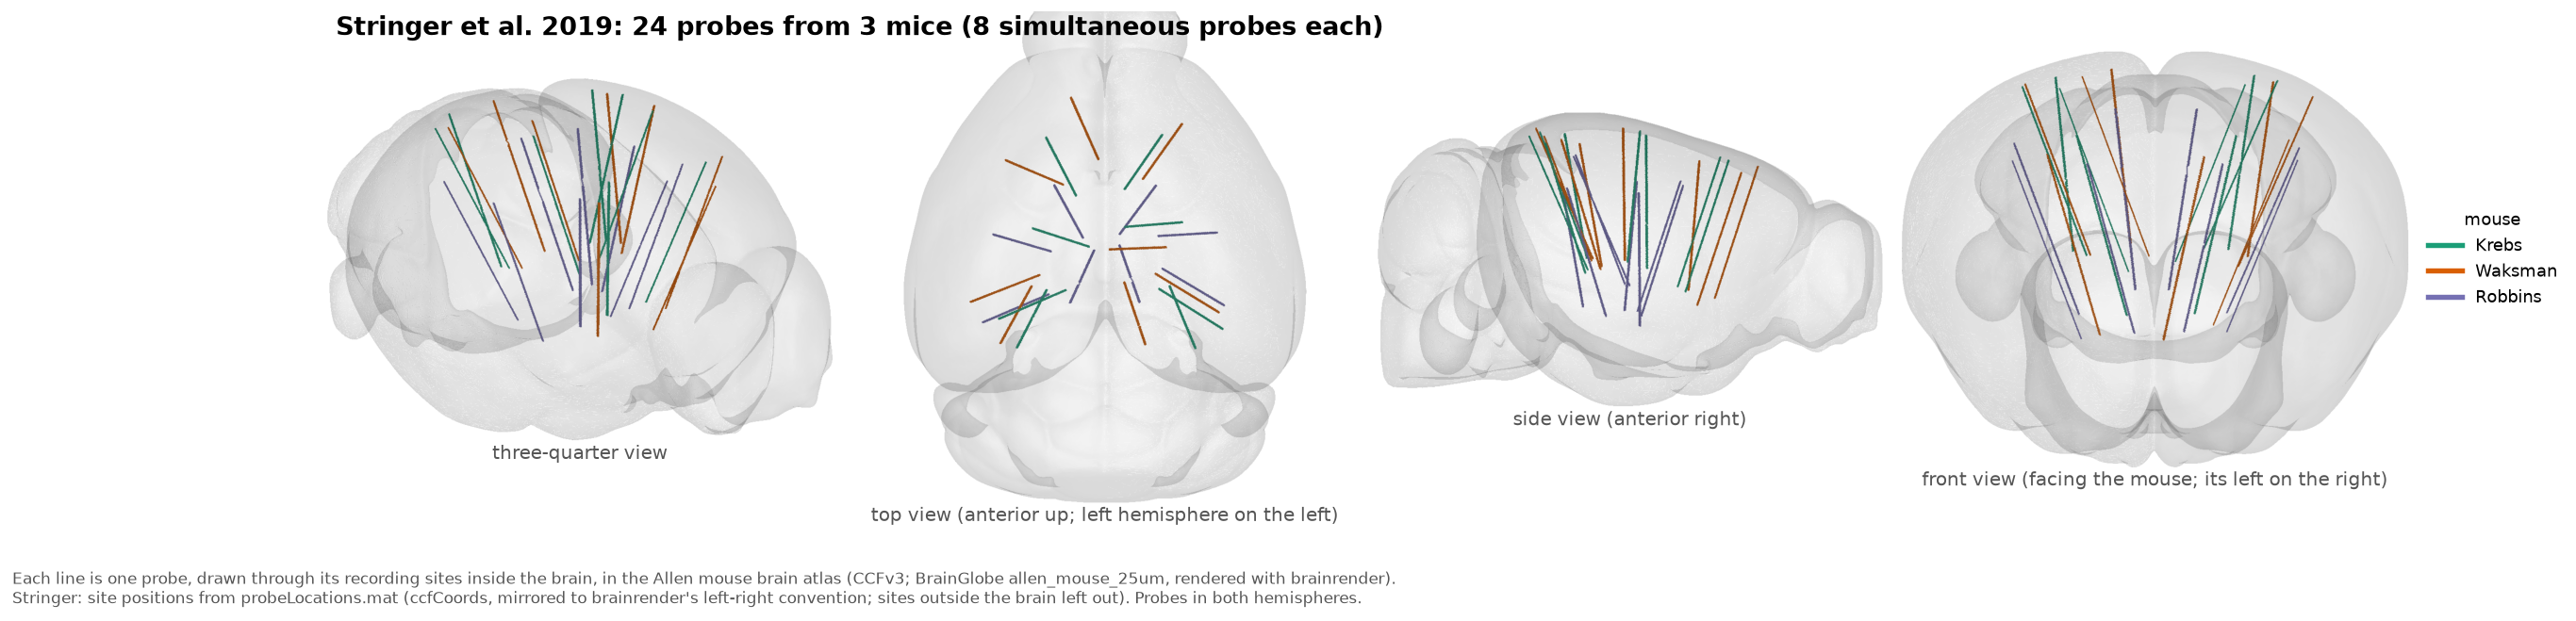

In [6]:
display(Image(filename=str(FIGURE_DIR / "stringer_probes.png")))

### Neurons per probe

Units on each of the 8 probes, per mouse (all 8 recorded at once, so a session's neurons are the sum). The label
above each bar is the probe's coarse path, brain surface to tip, from the authors' `probeBorders.mat`.

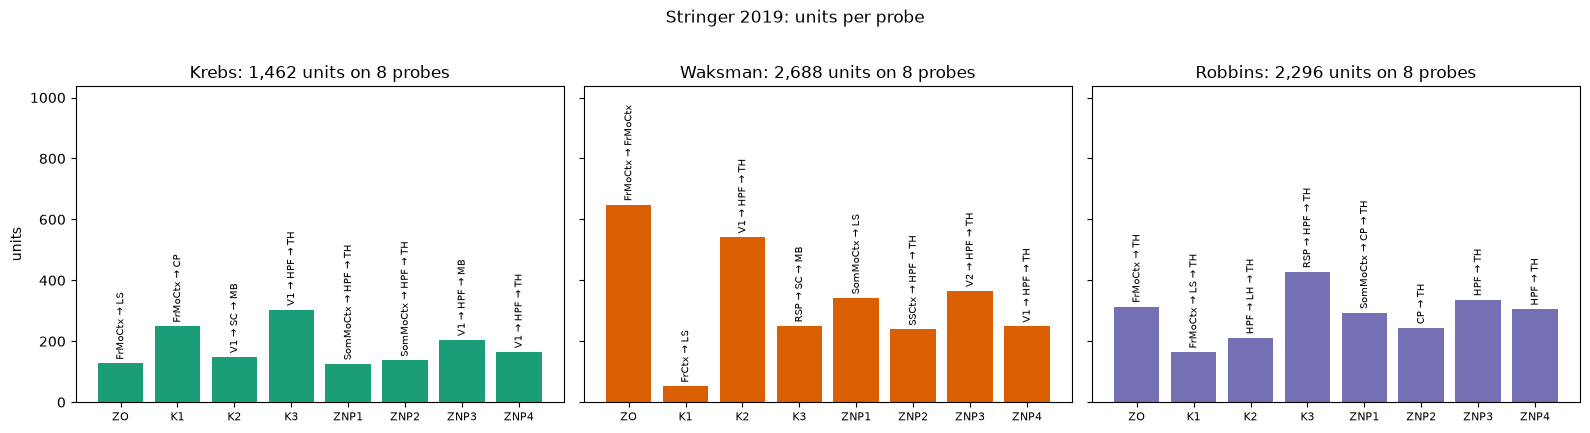

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, m in zip(axes, MICE):
    p = probes[probes.session == m].sort_values("probe")
    ax.bar(np.arange(len(p)), p.units, color=MOUSE_COLOR[m])
    for x, (n, s) in enumerate(zip(p.units, p.areas_coarse)):
        ax.text(x, n + 12, " → ".join(a.split(" ")[0] for a in s.split(", ")), rotation=90, ha="center", va="bottom",
                fontsize=7.5)
    ax.set_xticks(np.arange(len(p)), p.probe_name, fontsize=8)
    ax.set_ylim(0, probes.units.max() * 1.6)
    ax.set_title(f"{m}: {p.units.sum():,} units on 8 probes")
axes[0].set_ylabel("units")
fig.suptitle("Stringer 2019: units per probe", y=1.02)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "stringer_neurons_per_probe.png", dpi=150, bbox_inches="tight")
plt.show()

### Firing rates

One rate per unit: spikes over its probe's first-to-last spike (the spontaneous window). One outline per mouse.

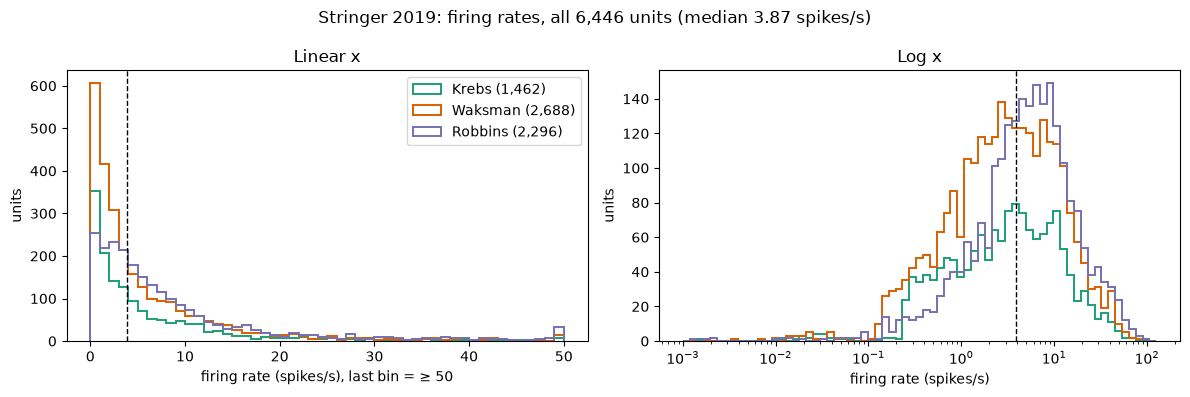

,count,mean,std,min,25%,50%,75%,max
session,,,,,,,,
Krebs,1462.0,6.18,8.37,0.0,1.05,3.28,8.04,71.29
Waksman,2688.0,6.19,8.66,0.0,1.15,3.05,7.93,93.96
Robbins,2296.0,8.84,10.84,0.0,2.41,5.28,10.62,91.03


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for m in MICE:
    fr = units.rate_hz[units.session == m]
    axes[0].hist(fr.clip(upper=50), bins=np.arange(0, 51, 1), histtype="step", lw=1.4, color=MOUSE_COLOR[m],
                 label=f"{m} ({len(fr):,})")
    pos = fr[fr > 0]
    axes[1].hist(pos, bins=np.logspace(-3, 2.1, 70), histtype="step", lw=1.4, color=MOUSE_COLOR[m], label=m)
axes[0].set(xlabel="firing rate (spikes/s), last bin = ≥ 50", ylabel="units", title="Linear x")
axes[1].set(xscale="log", xlabel="firing rate (spikes/s)", ylabel="units", title="Log x")
for ax in axes:
    ax.axvline(units.rate_hz.median(), color="k", ls="--", lw=1)
axes[0].legend()
fig.suptitle(f"Stringer 2019: firing rates, all {len(units):,} units (median {units.rate_hz.median():.2f} spikes/s)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "stringer_firing_rates.png", dpi=150)
plt.show()
display(units.groupby("session").rate_hz.describe().loc[MICE].round(2))

### Brain regions

Each unit gets the CCF label of the probe site nearest its height (as in `ephysLoad.m`), then its major division
(layers merged; the same mapping as the coverage comparison). "outside" = fiber tracts, ventricles or sites labelled
root. All 8 of Robbins's probes end in thalamus, so most of its units are thalamic. The authors' own coarse areas are
in the table.

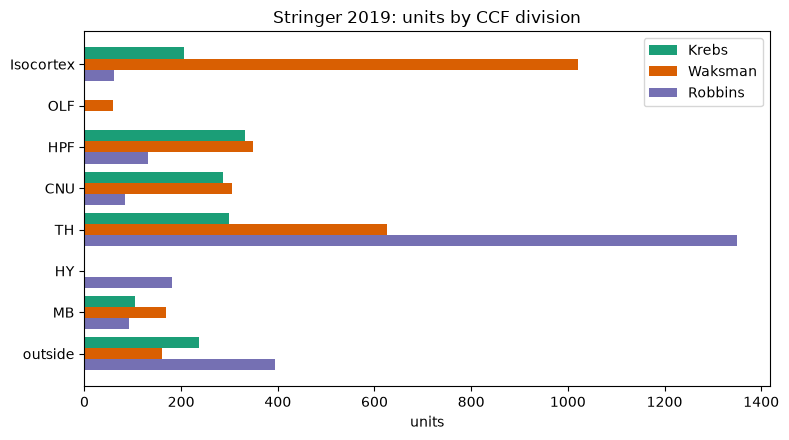

79 CCF regions (layers merged), 55 with ≥ 20 units; 127 distinct site labels


session,Krebs,Waksman,Robbins
authors' coarse area,,,
FrMoCtx,78,647,86
TH,227,638,1878
HPF,265,333,155
V1,334,251,0
SomMoCtx,91,220,10
LS,122,133,4
V2,0,124,0
RSP,0,112,10
SC,42,98,0


In [9]:
DIVS = ["Isocortex", "OLF", "HPF", "CTXsp", "CNU", "TH", "HY", "MB", "HB", "CB"]
div = units.assign(division=units.division.replace("", "outside"))
tab = pd.crosstab(div.division, div.session)[MICE].reindex([d for d in DIVS if d in set(div.division)] + ["outside"])
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(tab))[::-1]
for i, m in enumerate(MICE):
    ax.barh(y + (1 - i) * 0.27, tab[m], height=0.27, color=MOUSE_COLOR[m], label=m)
ax.set(yticks=y, yticklabels=tab.index, xlabel="units", title="Stringer 2019: units by CCF division")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "stringer_regions.png", dpi=150)
plt.show()
reg = units[units.region != ""]
print(f"{reg.region.nunique()} CCF regions (layers merged), {(reg.region.value_counts() >= 20).sum()} with ≥ 20 units;"
      f" {units.acronym.nunique()} distinct site labels")
display(pd.crosstab(units.area_coarse.replace("", "(none)"), units.session)[MICE].sort_values("Waksman", ascending=False)
        .rename_axis("authors' coarse area"))

### Raster

The session with the median number of units (Robbins, 2,296); 30 s starting 600 s into its spontaneous window.
Rows = units, grouped by probe (ZO at the bottom) and sorted by height (probe tip at the bottom of each band). Blue
lines separate probes; the label is the probe and its most common CCF regions (fiber tracts left out). Below: the first three face-motion
SVD components over the same 30 s (the behaviour the paper predicts activity from).

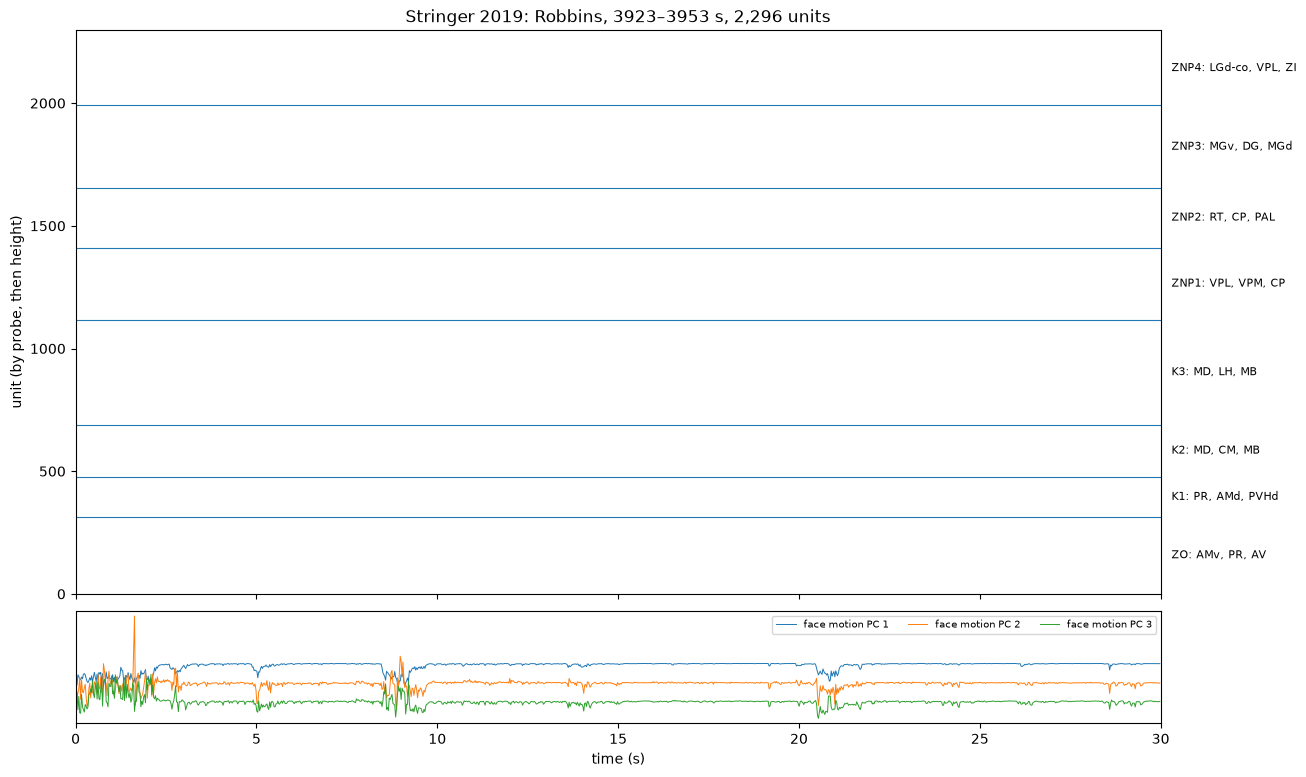

In [10]:
r = np.load(TABLES / "raster.npz", allow_pickle=True)
fig, (ax, bx) = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw=dict(height_ratios=[5, 1], hspace=0.05))
ax.scatter(r["spike_times"], r["spike_rows"], s=0.3, color="k", marker="|", linewidths=0.3, rasterized=True)
b = r["probe_bounds"]
for y in b[1:-1]:
    ax.axhline(y, color="C0", lw=0.8)
ru = units[units.session == str(r["session"])]
for k, name in enumerate(r["probe_names"]):
    g = ru[(ru.probe == k) & (ru.division != "")]  # fiber tracts and root left out of the label
    top = g.region.value_counts().head(3).index
    ax.text(30.3, (b[k] + b[k + 1]) / 2, f"{name}: {', '.join(top)}", va="center", fontsize=8)
ax.set(ylim=(0, b[-1]), ylabel="unit (by probe, then height)",
       title=f"Stringer 2019: {r['session']}, {float(r['t0']):.0f}–{float(r['t0']) + 30:.0f} s, {b[-1]:,} units")
for i in range(3):
    pc = r["face_pcs"][:, i]
    bx.plot(r["face_times"], (pc - pc.mean()) / pc.std() - 4 * i, lw=0.7, label=f"face motion PC {i + 1}")
bx.set(yticks=[], xlabel="time (s)", xlim=(0, 30))
bx.legend(loc="upper right", fontsize=7, ncol=3)
fig.savefig(FIGURE_DIR / "stringer_raster.png", dpi=150, bbox_inches="tight")
plt.show()

## Spreadsheet

- Same columns as the NLB / FALCON / IBL / Allen CSVs. CHANNELS = `N/A` (sorted units); TRIALS = `N/A` (spontaneous).
- Length: 1 decimal minute. RAW / BENCHMARK: 3 decimal GB.
- This cell writes `tutorials/stringer_datasets.csv`.

In [11]:
fr = units.rate_hz
p = probes.groupby("session").units
notes = (
    f"Stringer et al. 2019 (Science) eight-probe release (figshare 10.25378/janelia.7739750, CC BY-NC 4.0; raw face "
    f"videos 10.25378/janelia.8378360, CC BY 4.0): {len(sessions)} mice, one session each, 8 simultaneous "
    f"Neuropixels probes per mouse ({len(probes)} total) in both hemispheres (frontal, sensorimotor and visual "
    f"cortex, hippocampus, striatum, thalamus, midbrain); {probes.units.min()}–{probes.units.max()} units per probe. "
    f"No task or stimuli: spontaneous activity with the face filmed at ~40 Hz. TRIALS N/A; CHANNELS N/A (sorted units). "
    f"NEURONS = every released cluster (no QC labels in the release): Krebs 1,462, Waksman 2,688, Robbins 2,296 "
    f"(paper: 1,462 / 2,668 / 2,296). Regions: nearest-site CCF label from probeLocations.mat; "
    f"{units[units.region != ''].region.nunique()} CCF regions; by division TH {(units.division == 'TH').sum():,}, "
    f"Isocortex {(units.division == 'Isocortex').sum():,}, HPF {(units.division == 'HPF').sum():,}, "
    f"CNU {(units.division == 'CNU').sum():,}, MB {(units.division == 'MB').sum():,}, "
    f"HY {(units.division == 'HY').sum():,}, OLF {(units.division == 'OLF').sum():,}, "
    f"outside/fiber {(units.division == '').sum():,}. Probe-to-location pairing as in the released ephysLoad.m; the "
    f"authors' alignFaces30Hz.m reorders probes [1 2 7 8 3 4 5 6], and the data cannot tell which is right. "
    f"LENGTH = first-to-last spike per session, summed (the release holds only the spontaneous window). "
    f"RAW = both figshare items: spikes + face motion {release[release.item == 'spikes_behaviour'].size_bytes.sum() / GB:.3f} GB "
    f"+ raw face videos {release[release.item == 'raw_videos'].size_bytes.sum() / GB:.3f} GB (no raw voltage or LFP public). "
    f"BENCHMARK = spike times + cluster ids (12 B/spike, {spike_bytes / GB:.3f} GB) + face-motion SVD, 500 components, "
    f"and frame times for the frames inside the spontaneous window ({face_bytes / GB:.3f} GB; the video starts ~1 h "
    f"before the released spikes) + probe locations. Labels: face-motion SVD (behaviour), no task variables."
)
row = {
    "DATASET": "Stringer 2019 eight-probe", "ANIMAL": "Mouse", "SUBJECTS": len(sessions), "TRIALS": "N/A",
    "TOTAL CHANNELS": "N/A", "MEDIAN CHANNELS": "N/A", "TOTAL NEURONS": int(sessions.units.sum()),
    "MEDIAN NEURONS": int(sessions.units.median()), "RECORDING LENGTH (min)": round(sessions.length_min.sum(), 1),
    "RAW DATASET SIZE (GB)": round(raw_bytes / GB, 3), "BENCHMARK DATASET SIZE (GB)": round(benchmark_bytes / GB, 3),
    "NOTES": notes,
    "BASIC STATS": f"firing rate: mean {fr.mean():.2f}, median {fr.median():.2f} spikes/s",
}
csv = pd.DataFrame([row])
csv.to_csv(REPO / "tutorials" / "stringer_datasets.csv", index=False)
display(csv.drop(columns="NOTES").T)
print(notes)

,0
DATASET,Stringer 2019 eight-probe
ANIMAL,Mouse
SUBJECTS,3
TRIALS,N/A
TOTAL CHANNELS,N/A
MEDIAN CHANNELS,N/A
TOTAL NEURONS,6446
MEDIAN NEURONS,2296
RECORDING LENGTH (min),100.2
RAW DATASET SIZE (GB),38.509


Stringer et al. 2019 (Science) eight-probe release (figshare 10.25378/janelia.7739750, CC BY-NC 4.0; raw face videos 10.25378/janelia.8378360, CC BY 4.0): 3 mice, one session each, 8 simultaneous Neuropixels probes per mouse (24 total) in both hemispheres (frontal, sensorimotor and visual cortex, hippocampus, striatum, thalamus, midbrain); 52–648 units per probe. No task or stimuli: spontaneous activity with the face filmed at ~40 Hz. TRIALS N/A; CHANNELS N/A (sorted units). NEURONS = every released cluster (no QC labels in the release): Krebs 1,462, Waksman 2,688, Robbins 2,296 (paper: 1,462 / 2,668 / 2,296). Regions: nearest-site CCF label from probeLocations.mat; 79 CCF regions; by division TH 2,275, Isocortex 1,289, HPF 811, CNU 675, MB 365, HY 182, OLF 58, outside/fiber 791. Probe-to-location pairing as in the released ephysLoad.m; the authors' alignFaces30Hz.m reorders probes [1 2 7 8 3 4 5 6], and the data cannot tell which is right. LENGTH = first-to-last spike per session, sum